# <span style='color:deepskyblue'>Chapter 2</span>

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
#Random number configuration
rng = np.random.default_rng()

------------------------------------

##### b) Write a MATLAB script that can generate trajectories for bacteria motion based on the probability distribution:

$$
P(\phi) = \frac{1}{2\pi}\left(1 + A\cos\phi\right)
$$

Probability Denisty:

In [4]:
def probability_density(phi, A):
    """
    P(phi) from Eq. 2.3. 
    A in [0, 1] controls the bias strength.
    """
    return (1.0 / (2.0 * np.pi)) * (1.0 + A * np.cos(phi))

Rejection Sampling:

In [5]:
def sample_phi(A, rng=rng):
    """
    Draw a single angle phi from P(phi; A) using rejection sampling
 
    P(phi) is maximal at phi = 0, where P(0) = (1 + A) / (2*pi) -> Rejection PDF height
    """
    p_max = (1.0 + A) / (2.0 * np.pi)


    # Add ratio ratio between number accepted trials and total number of trials
 
    while True:
        phi_trial = rng.uniform(0.0, 2.0 * np.pi) #draw random phi_trial in [0, 2pi]
        y_trial = rng.uniform(0.0, p_max) #draw random y_trial in [0, p_max]
        if y_trial <= probability_density(phi_trial, A):
            return phi_trial

Trajectory Generation:

In [6]:
def step_xy(r, phi, x0, y0):
    """
    Cartesian displacement of one step (Eq. 2.2).
    """
    x = x0 + r * np.cos(phi)
    y = y0 + r * np.sin(phi)
    return x, y


def generate_trajectory(num_steps, r, A):
    """
    Build one N-step trajectory. Returns an (num_steps+1, 2) array
    of (x, y) positions, starting at the origin.
    """
    positions = np.zeros((num_steps + 1, 2))
    
    for i in range(1, num_steps + 1):
        phi = sample_phi(A)
        x_prev, y_prev = positions[i - 1]
        positions[i] = step_xy(r, phi, x_prev, y_prev)
    return positions

In [7]:
def verify_sampling(A, n_samples=200_000, n_bins=60):

    samples = np.array([sample_phi(A) for _ in range(n_samples)])
 
    phi_grid = np.linspace(0, 2 * np.pi, 400) # X axis bins
    theory = probability_density(phi_grid, A)
 
    plt.figure(figsize=(7, 4))
    plt.hist(samples, bins=n_bins, density=True, alpha=0.6,
              label="sampled histogram")
    plt.plot(phi_grid, theory, "r-", lw=2, label="P(phi) theory")
    plt.title(f"Rejection sampling check (A = {A})")
    plt.xlabel("phi (rad)")
    plt.ylabel("probability density")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
 

In [8]:
def plot_trajectories(num_steps, num_bacteria, r, A):
    plt.figure(figsize=(7, 5))
    
    for i in range(num_bacteria):
        traj = generate_trajectory(num_steps, r, A)
        x, y = traj[:, 0], traj[:, 1]
 
        plt.plot(x, y, linewidth=0.6, label=f"Bacteria {i+1}")
        plt.scatter(x[0], y[0], color="black", zorder=5)   # start
        plt.scatter(x[-1], y[-1], color="red", zorder=5)   # end
 
    plt.title(f"Bacteria trajectories (A = {A}, N = {num_steps} steps, {num_bacteria} bacteria)")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis("equal")
    plt.grid(alpha=0.3)
    if num_bacteria <= 10:
        plt.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

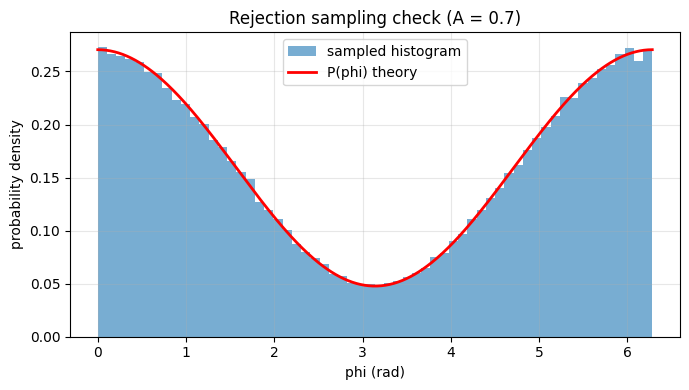

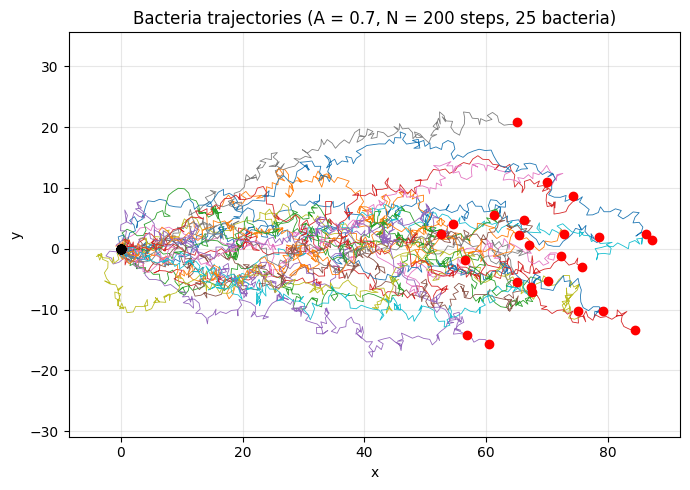

In [9]:
A = 0.7   # bias strength, 0 <= A <= 1
r = 1.0   # fixed step length
 
verify_sampling(A)
plot_trajectories(num_steps=200, num_bacteria=25, r=r, A=A)

------------------------------------

Rejection Sampling and X calculation

In [10]:
# Same rejection-sampling algorithm as sample_phi, but drawing many angles at once.
def sample_phi_vec(A, size):
    """Rejection sampling of `size` angles from P(phi; A)."""
    p_max = (1.0 + A) / (2.0 * np.pi)
    out = np.empty(size) # create an empty array to hold the accepted samples
    filled = 0
    while filled < size:
        n = size - filled # n is the number of angles still needed
        phi = rng.uniform(0.0, 2.0 * np.pi, n)
        y = rng.uniform(0.0, p_max, n)
        accepted = phi[y <= probability_density(phi, A)]
        out[filled:filled + accepted.size] = accepted # fill the output array with accepted samples
        filled += accepted.size
    return out
 
# Final x-position X of M independent bacteria, each taking N steps.
def final_x(A, N, M, r):
    """Final x-position X of M independent bacteria, each taking N steps."""
    phi = sample_phi_vec(A, M * N).reshape(M, N)
    return (r * np.cos(phi)).sum(axis=1)

##### d) Prove that your MATLAB script reproduces equation: 

$$
\langle X\rangle = \frac{1}{2}ANr
$$

##### Vary A and N in your calculations.

In [11]:
def measure(A, N, M, r):
    """Return (sample mean of X, standard error of the mean, theory 0.5*A*N*r)."""
    X = final_x(A, N, M, r)
    mean = X.mean()
    sem = X.std(ddof=1) / np.sqrt(M) # standard error of the mean
    theory = 0.5 * A * N * r
    return mean, sem, theory

In [12]:
# Check Eq. 2.5: <X> = 0.5 * A * N * r and plot results for varying A and varying N.
def check_eq_2_5(r=1.0, M=4000, N_fixed=100,
                 A_values=None, N_values=None, A_list=(0.25, 0.5, 0.75, 1.0)):
    """Vary A (fixed N) and vary N (several A); print table and plot."""
    if A_values is None:
        A_values = np.linspace(0.0, 1.0, 11)
    if N_values is None:
        N_values = np.array([10, 20, 50, 100, 200, 500, 1000])
 
    # Experiment 1: vary A at fixed N
    res1 = [measure(A, N_fixed, M, r) for A in A_values]

    # Experiment 2: vary N at several fixed A
    res2 = {A: [measure(A, N, M, r) for N in N_values] for A in A_list}
 
    # ---- table with z-scores: z = (sim - theory) / SEM ----
    print(f"Experiment 1: N = {N_fixed}, M = {M}")
    print(f"{'A':>5} {'<X> sim':>10} {'+/- SEM':>9} {'theory':>9} {'z':>6}")
    for A, (m, s, t) in zip(A_values, res1):
        print(f"{A:5.2f} {m:10.3f} {s:9.3f} {t:9.3f} {(m - t) / s:6.2f}")
 
    print(f"\nExperiment 2: M = {M}")
    print(f"{'A':>5} {'N':>6} {'<X> sim':>10} {'+/- SEM':>9} {'theory':>9} {'z':>6}")
    for A in A_list:
        for N, (m, s, t) in zip(N_values, res2[A]):
            print(f"{A:5.2f} {N:6d} {m:10.3f} {s:9.3f} {t:9.3f} {(m - t) / s:6.2f}")
 
    all_z = [(m - t) / s for (m, s, t) in res1] + \
            [(m - t) / s for A in A_list for (m, s, t) in res2[A]]
    print(f"\n|z| <= 2 for {np.mean(np.abs(all_z) <= 2) * 100:.0f}% of points")
 
    # ---- figure ----
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

    # Experiment 1: vary A at fixed N
    m, s, _ = map(np.array, zip(*res1))
    Af = np.linspace(0, 1, 100)
    ax[0].plot(Af, 0.5 * Af * N_fixed * r, "k-", label=r"theory $\frac{1}{2}ANr$")
    ax[0].errorbar(A_values, m, yerr=s, fmt="o", capsize=3, label="simulation")
    ax[0].set(xlabel="A", ylabel=r"$\langle X\rangle$",
              title=f"Varying A (N = {N_fixed}, {M} bacteria)")
    ax[0].legend()
    ax[0].grid(alpha=0.3)

    # Experiment 2: vary N at several fixed A
    Nf = np.linspace(0, np.max(N_values), 100)  # fine grid for theory lines
    for A in A_list:
        m, s, _ = map(np.array, zip(*res2[A]))
        line, = ax[1].plot(Nf, 0.5 * A * Nf * r, "-", lw=1)
        ax[1].errorbar(N_values, m, yerr=s, fmt="o", capsize=3,
                       color=line.get_color(), label=f"A = {A}")
    ax[1].set(xlabel="N (steps)", ylabel=r"$\langle X\rangle$",
              title=f"Varying N ({M} bacteria); lines = theory")
    ax[1].legend()
    ax[1].grid(alpha=0.3)
 
    plt.tight_layout()
    plt.show()


Experiment 1: N = 100, M = 10000
    A    <X> sim   +/- SEM    theory      z
 0.00      0.043     0.070     0.000   0.61
 0.10      4.958     0.070     5.000  -0.60
 0.20     10.032     0.069    10.000   0.46
 0.30     15.007     0.069    15.000   0.11
 0.40     19.948     0.068    20.000  -0.76
 0.50     25.035     0.066    25.000   0.53
 0.60     29.914     0.064    30.000  -1.35
 0.70     34.896     0.061    35.000  -1.71
 0.80     40.007     0.059    40.000   0.12
 0.90     45.104     0.055    45.000   1.90
 1.00     50.080     0.050    50.000   1.60

Experiment 2: M = 10000
    A      N    <X> sim   +/- SEM    theory      z
 0.25     10      1.268     0.022     1.250   0.82
 0.25     20      2.467     0.031     2.500  -1.05
 0.25     50      6.203     0.049     6.250  -0.96
 0.25    100     12.466     0.070    12.500  -0.49
 0.25    200     25.173     0.098    25.000   1.76
 0.25    500     62.471     0.156    62.500  -0.18
 0.25   1000    125.120     0.218   125.000   0.55
 0.50 

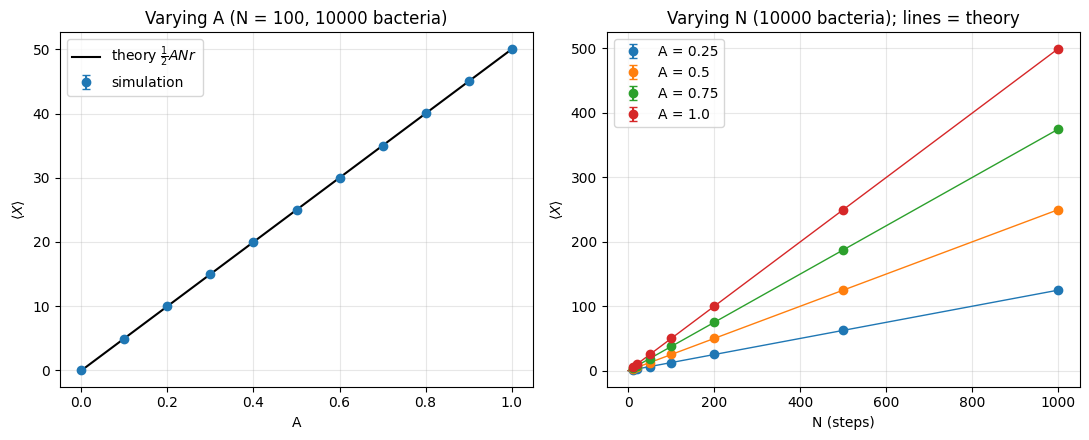

In [13]:
check_eq_2_5(r=r, M=10000)

------------------------------------

##### f) Prove that your script reproduces equation 2.7. Vary N in your calculations.


$$
\langle X^2\rangle - \langle X\rangle^2 = \tfrac{1}{2} N r^2\left(1 - \tfrac{1}{2}A^2\right)\;
$$

In [14]:
def variance(A, N, M, r):
    """Return (variance of X, standard error of that variance,
    theory 0.5 * N * r**2 * (1 - 0.5 * A**2))."""
    X = final_x(A, N, M, r)

    variance = (X**2).mean() - X.mean()**2

    sem_var = np.std((X - X.mean())**2) / np.sqrt(M) # standard error of the variance

    theory = 0.5 * N * r**2 * (1 - 0.5 * A**2)

    return variance, sem_var, theory

In [15]:

def check_eq_2_7(r=1.0, M=5000, N_values=None, A_list=(0.25, 0.5, 0.75, 1.0)):
    """
    Check Eq. 2.7:  <X^2> - <X>^2 = 0.5 * N * r^2 * (1 - 0.5 * A^2)
    by varying N (for several fixed values of A).
    Uses measure(A, N, M, r) -> (variance, standard error of variance, theory).
    """
    if N_values is None:
        N_values = np.array([10, 20, 50, 100, 200, 500, 1000])

    # 1) run the simulation for every (A, N)
    results = {}
    for A in A_list:
        results[A] = [variance(A, N, M, r) for N in N_values]

    # 2) table with z-scores: z = (simulation - theory) / standard error
    print(f"Check of Eq. 2.7 with M = {M} bacteria per point")
    print(f"{'A':>5} {'N':>6} {'Var sim':>10} {'+/- SE':>9} {'theory':>10} {'z':>6}")
    all_z = []
    for A in A_list:
        for N, (var, se, theory) in zip(N_values, results[A]):
            z = (var - theory) / se
            all_z.append(z)
            print(f"{A:5.2f} {N:6d} {var:10.3f} {se:9.3f} {theory:10.3f} {z:6.2f}")

    frac = np.mean(np.abs(all_z) <= 2) * 100
    print(f"\n|z| <= 2 for {frac:.0f}% of the points")

    plt.figure(figsize=(6.5, 4.5))
    N_line = np.linspace(0, np.max(N_values), 100)
    for A in A_list:
        var, se, theory = map(np.array, zip(*results[A]))

        # theory line and simulated points
        line, = plt.plot(N_line, 0.5 * N_line * r**2 * (1 - 0.5 * A**2), lw=1)
        plt.errorbar(N_values, var, yerr=se, fmt="o", capsize=3,
                        color=line.get_color(), label=f"A = {A}")

    plt.xlabel("N (steps)")
    plt.ylabel(r"$\langle X^2\rangle - \langle X\rangle^2$")
    plt.title(f"Variance vs N ({M} bacteria); lines = theory")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Check of Eq. 2.7 with M = 10000 bacteria per point
    A      N    Var sim    +/- SE     theory      z
 0.25     10      4.699     0.065      4.844  -2.24
 0.25     20      9.723     0.136      9.688   0.26
 0.25     50     24.997     0.352     24.219   2.21
 0.25    100     47.952     0.669     48.438  -0.73
 0.25    200     96.180     1.322     96.875  -0.53
 0.25    500    240.454     3.383    242.188  -0.51
 0.25   1000    479.301     6.710    484.375  -0.76
 0.50     10      4.372     0.059      4.375  -0.05
 0.50     20      8.699     0.121      8.750  -0.42
 0.50     50     22.148     0.310     21.875   0.88
 0.50    100     44.586     0.620     43.750   1.35
 0.50    200     89.286     1.262     87.500   1.42
 0.50    500    218.702     3.067    218.750  -0.02
 0.50   1000    439.748     6.200    437.500   0.36
 0.75     10      3.544     0.050      3.594  -1.01
 0.75     20      7.201     0.101      7.188   0.14
 0.75     50     17.844     0.250     17.969  -0.50
 0.75    100 

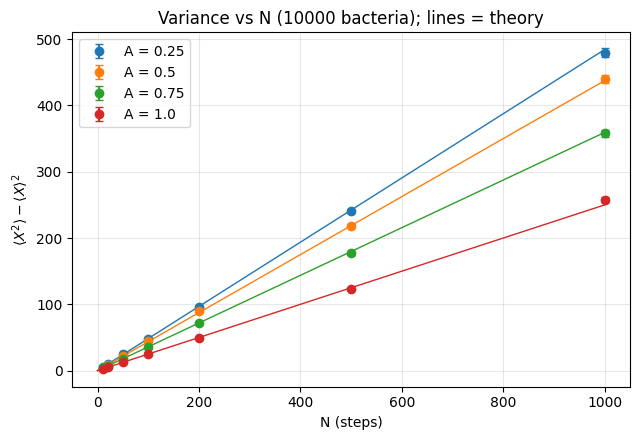

In [16]:
check_eq_2_7(r=r, M=10000)

------------------------------------

##### g) Rewrite your program such that it makes use of importance sampling. Prove that the efficiency (ratio between number accepted trials and total number of trials) has been improved, while the results are still correct.

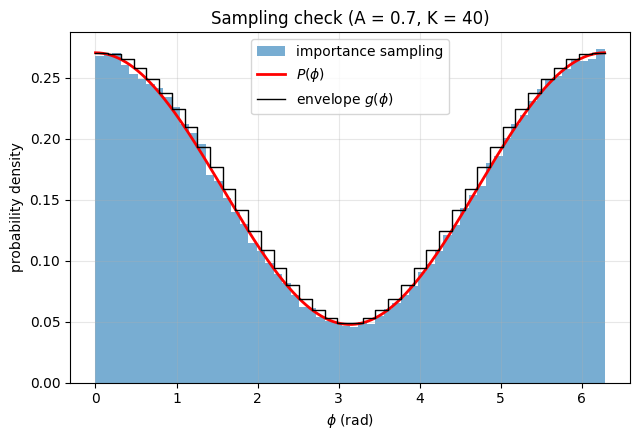

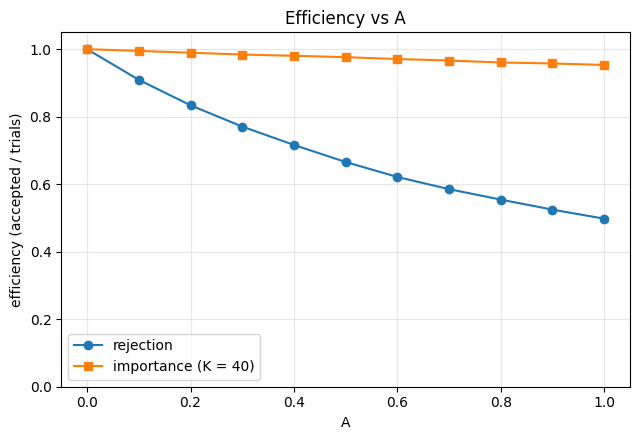

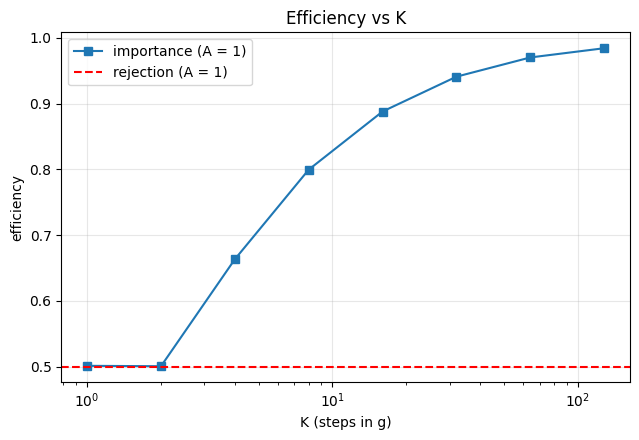

In [ ]:
def probability_density(phi, A):
    return (1.0 / (2.0 * np.pi)) * (1.0 + A * np.cos(phi))

# Rejection sampling of phi with number of trials
def sample_phi_rejection(A, size):
    """Returns (samples, total number of trials)."""
    p_max = (1.0 + A) / (2.0 * np.pi)
    out = np.empty(size)
    filled, trials = 0, 0
    while filled < size:
        n = size - filled
        phi = rng.uniform(0.0, 2.0 * np.pi, n)
        y = rng.uniform(0.0, p_max, n)
        accepted = phi[y <= probability_density(phi, A)]
        out[filled:filled + accepted.size] = accepted
        filled += accepted.size
        trials += n
    return out, trials


# g(phi) staircase with K steps, G piecewise linear
def build_envelope_g(A, K):
    edges = np.linspace(0.0, 2.0 * np.pi, K + 1) # create K+1 edges from 0 to 2pi
    left, right = edges[:-1], edges[1:] # left and right edges of each step
    width = 2.0 * np.pi / K # width of each step
    g = np.maximum(probability_density(left, A), probability_density(right, A)) # g(phi) = max(P(left), P(right)) for each step
    G_right = np.cumsum(g * width)
    G_left = G_right - g * width
    G_max = G_right[-1]
    return left, g, G_left, G_right, G_max


# Inverse transform on G, y in [0, g(phi)], accept if y <= P(phi)
def sample_phi_importance(A, size, K):
    """Returns (samples, total number of trials)."""
    left, g, G_left, G_right, G_max = build_envelope_g(A, K)
    out = np.empty(size)
    filled, trials = 0, 0
    while filled < size:
        n = size - filled
        x = rng.uniform(0.0, G_max, n) # x in [0, G_max]
        k = np.minimum(np.searchsorted(G_right, x, side="right"), K - 1) # find the index of the step for each x
        phi = left[k] + (x - G_left[k]) / g[k] # phi = G^-1(x)
        y = rng.uniform(0.0, 1.0, n) * g[k] # y in [0, g(phi)]
        accepted = phi[y <= probability_density(phi, A)]
        out[filled:filled + accepted.size] = accepted
        filled += accepted.size
        trials += n
    return out, trials


def compare_efficiency(A_values, K, n_samples):
    eff_rej, eff_imp = [], []
    for A in A_values:
        _, t_r = sample_phi_rejection(A, n_samples)
        _, t_i = sample_phi_importance(A, n_samples, K)
        e_r, e_i = n_samples / t_r, n_samples / t_i # efficiency = accepted / trials
        eff_rej.append(e_r)
        eff_imp.append(e_i)
    return np.array(eff_rej), np.array(eff_imp)


def make_plots(A, K, n_samples):
    # Histogram 
    samples, _ = sample_phi_importance(A, n_samples, K)
    left, g, _, _, _ = build_envelope_g(A, K)
    phi_grid = np.linspace(0, 2 * np.pi, 400)

    plt.figure(figsize=(6.5, 4.5))
    plt.hist(samples, bins=60, density=True, alpha=0.6, label="importance sampling")
    plt.plot(phi_grid, probability_density(phi_grid, A), "r-", lw=2, label=r"$P(\phi)$")
    plt.step(np.append(left, 2 * np.pi), np.append(g, g[-1]), where="post",
             color="k", lw=1, label=r"envelope $g(\phi)$")
    plt.xlabel(r"$\phi$ (rad)")
    plt.ylabel("probability density")
    plt.title(f"Sampling check (A = {A}, K = {K})")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Efficiency comparison
    A_vals = np.linspace(0, 1, 11)
    e_r, e_i = compare_efficiency(A_vals, K, n_samples=50_000)

    plt.figure(figsize=(6.5, 4.5))
    plt.plot(A_vals, e_r, "o-", label="rejection")
    plt.plot(A_vals, e_i, "s-", label=f"importance (K = {K})")
    plt.xlabel("A")
    plt.ylabel("efficiency (accepted / trials)")
    plt.title("Efficiency vs A")
    plt.ylim(0, 1.05)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Efficiency vs K
    K_vals = np.array([1, 2, 4, 8, 16, 32, 64, 128])
    eff = [50_000 / sample_phi_importance(1.0, 50_000, k)[1] for k in K_vals]
    
    plt.figure(figsize=(6.5, 4.5))
    plt.semilogx(K_vals, eff, "s-", label="importance (A = 1)")
    plt.axhline(0.5, color="r", ls="--", label="rejection (A = 1)")
    plt.xlabel("K (steps in g)")
    plt.ylabel("efficiency")
    plt.title("Efficiency vs K")
    plt.legend(); plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

make_plots(0.7, 40, 200_000)

In [21]:
def compare_efficiency(A_values, K, n_samples):
    print(f"{'A':>5} | {'':>16}{'efficiency':<24} | (K = {K})")
    print(f"{'':>5} | {'rejection':>10} {'1/(1+A)':>8} | "
          f"{'importance':>10} {'G_max':>8} ")
    eff_rej, eff_imp = [], []
    for A in A_values:
        _, t_r = sample_phi_rejection(A, n_samples)
        _, t_i = sample_phi_importance(A, n_samples, K)
        e_r, e_i = n_samples / t_r, n_samples / t_i # efficiency = accepted / trials
        G_max = build_envelope_g(A, K)[4] 
        print(f"{A:5.2f} | {e_r:10.4f} {1/(1+A):8.4f} | {e_i:10.4f} {1/G_max:8.4f}")
        eff_rej.append(e_r)
        eff_imp.append(e_i)
    return np.array(eff_rej), np.array(eff_imp)

# Correctness: reproduce Eq. 2.5 and 2.7 with importance sampling
def final_x_importance(A, N, M, r, K=20):
    phi, _ = sample_phi_importance(A, M * N, K)
    return (r * np.cos(phi.reshape(M, N))).sum(axis=1)


def check_moments(A_list=(0.25, 0.5, 0.75, 1.0), N=100, M=10_000, r=1.0, K=20):
    print(f"\nN = {N}, M = {M} bacteria, K = {K}")
    print(f"{'A':>5} | {'<X> sim':>9} {'+-':>6} {'theory':>8} | "
          f"{'Var sim':>9} {'theory':>8}")
    for A in A_list:
        X = final_x_importance(A, N, M, r, K)
        mean, sem = X.mean(), X.std(ddof=1) / np.sqrt(M)
        var = X.var()
        print(f"{A:5.2f} | {mean:9.3f} {sem:6.3f} {0.5*A*N*r:8.3f} | "
              f"{var:9.3f} {0.5*N*r**2*(1-0.5*A**2):8.3f}")

check_moments()


N = 100, M = 10000 bacteria, K = 20
    A |   <X> sim     +-   theory |   Var sim   theory
 0.25 |    12.484  0.069   12.500 |    48.034   48.438
 0.50 |    25.126  0.066   25.000 |    43.283   43.750
 0.75 |    37.439  0.060   37.500 |    36.006   35.938
 1.00 |    50.100  0.050   50.000 |    24.937   25.000
